<a id="chapter-08"></a>

# Chapter 08 · DQN Extensions / DQN 扩展

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 Double、Dueling、Noisy、PER、n-step、Distributional DQN
- 知道每项扩展解决哪个问题
- 理解 Rainbow 的组合思路

**开始前最好已经会：**

- 能完整解释基础 DQN
- 理解 TD error
- 熟悉概率分布和期望的直觉


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Basic and tuned DQN | baseline 与公平比较 | 详细 |
| N-step DQN | 第 7 章推导与源码 | 详细 |
| Double DQN | 选择/评价分离 | 详细 |
| Noisy networks | 参数噪声精读 | 详细 |
| Prioritized replay | 概率与重要性权重 | 详细 |
| Dueling DQN | 可辨识分解 | 详细 |
| Categorical DQN | 分布投影说明与实验 | 详细 |
| Combining everything / Rainbow | 组合表与源码路线 | 完整 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

DQN 不是一个不可改变的整体。过估计、探索、样本利用和表示能力分别有不同的病因，也应使用不同的药。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

扩展分别针对过估计、表示、探索、采样效率、信用分配和回报分布；它们并非互斥，因此可组合成 Rainbow。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $\delta_i$ | 第 $i$ 条经验的 TD error | PER priority 的依据 |
| $V(s)$ | 状态本身的价值 | Dueling value stream |
| $A(s,a)$ | 动作相对平均水平的优势 | Dueling advantage stream |
| $Z(s,a)$ | 随机回报分布 | distributional RL 的预测对象 |
| $n$ | n-step 长度 | 信用传播速度与方差的折中 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. Double DQN：把“选择”与“评价”拆开

同一组带噪估计既选最大动作又报告其数值，会偏向被高估的动作。Double DQN 用 online network 选择：

$$a^*=\arg\max_a Q_\theta(s',a)$$

再用 target network 评价：

$$y=r+\gamma Q_{\theta^-}(s',a^*)$$

它不能消除所有误差，但减少了 max 带来的系统性正偏差。

### 2. Dueling：解决动作难区分时的表示问题

直接写 $Q=V+A$ 不可辨识：给 $V$ 加常数、给所有 $A$ 减同一常数，Q 不变。减去 advantage 均值固定了一个规范：

$$Q(s,a)=V(s)+A(s,a)-\frac1{|\mathcal A|}\sum_{a'}A(s,a')$$

### 3. PER：把训练预算花在误差大的样本上

$P(i)=p_i^\alpha/\sum_jp_j^\alpha$ 改变了采样分布，因此用
$w_i=(NP(i))^{-\beta}$ 部分校正偏差。$\alpha=0$ 退化为均匀采样，$\beta\to1$ 时校正更充分。

### 4. Distributional：不只预测均值

Bellman distributional target 处理随机回报分布 $Z$。Categorical DQN 把概率质量投影到固定 support；Q 值只是该分布的期望 $\sum_i p_i z_i$。


## 4. 手算一个最小例子


online 下一状态 Q 为 `[2,3,1]`，所以选择动作 1；target Q 为 `[2.5,2,4]`。

- 普通 DQN 用 target 自己的最大值 4
- Double DQN 在 online 选择的动作 1 上读取 target，得到 2

这个刻意构造的例子显示“谁负责选、谁负责评”会改变目标。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 最常用的三个公式

Double DQN：
$$y=r+\gamma Q_{\theta^-}\!\left(s',\arg\max_a Q_\theta(s',a)\right)$$

Dueling：
$$Q(s,a)=V(s)+A(s,a)-\frac1{|\mathcal A|}\sum_{a'}A(s,a')$$

Prioritized replay：$p_i\propto(|\delta_i|+\varepsilon)^\alpha$，重要性权重 $w_i=(N P(i))^{-\beta}$。

[扩展部分](#extension) 补充 NoisyNet、categorical distribution 与组合选择。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $a^*=\arg\max Q_\theta$ | `online_next.argmax(...)` | online 只负责选择 |
| $Q_{\theta^-}(s',a^*)$ | `target_next.gather(..., chosen_action)` | target 负责评价 |
| $V(s)$ | dueling 的 value head，shape `(B,1)` | 所有动作共享 |
| $A(s,a)$ | advantage head，shape `(B,A)` | 动作差异 |
| 去均值 | `advantage.mean(dim=1, keepdim=True)` | 保持 batch/action 维正确 |
| $p_i,w_i$ | priority sampler 与 loss weight | 采样概率和偏差校正 |

**从公式过渡到代码时：**下面用固定张量对比普通 DQN 与 Double DQN 的目标动作，并验证 Dueling 聚合后的 advantage 均值被消除。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import torch

online_next = torch.tensor([[2.0, 3.0, 1.0]])
target_next = torch.tensor([[2.5, 2.0, 4.0]])
ordinary_target_q = target_next.max(dim=1).values
chosen_action = online_next.argmax(dim=1, keepdim=True)
double_target_q = target_next.gather(1, chosen_action).squeeze(1)
print("ordinary / double:", ordinary_target_q.item(), double_target_q.item())

value = torch.tensor([[5.0]])
advantage = torch.tensor([[1.0, -1.0, 2.0]])
q = value + advantage - advantage.mean(dim=1, keepdim=True)
print("dueling Q:", q, "mean Q:", q.mean().item())


ordinary / double: 4.0 2.0
dueling Q: tensor([[5.3333, 3.3333, 6.3333]]) mean Q: 5.0


### 怎样读运行结果

示例中 ordinary target=4、double target=2。Dueling 聚合后 Q 的动作均值等于 value；这正是减去平均 advantage 的效果。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
Rainbow 风格一次更新：
1. Noisy network 产生带参数噪声的 Q 分布，无需固定 epsilon schedule。
2. 从 prioritized buffer 按 P(i) 抽取 batch，并取得 importance weights。
3. 使用 n-step reward 构造更远期 target。
4. online network 选动作（Double）；target network 评价该动作。
5. categorical projection 把平移后的目标分布投影回固定 atoms。
6. 以 weighted cross-entropy 更新网络。
7. 用新的 per-sample loss/TD error 更新 priorities。
8. 周期同步 target，并 reset noisy layers。
```

组合前必须先有同一 baseline、同一评估协议和逐项 ablation，否则无法知道改进来自算法还是超参数。


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

# PER：从 priority 得到采样概率和归一化 importance weights。
priorities = np.array([1.0, 2.0, 4.0])
alpha, beta = 0.6, 0.4
probs = priorities ** alpha
probs /= probs.sum()
weights = (len(probs) * probs) ** (-beta)
weights /= weights.max()
print("P(i):", np.round(probs, 3), "weights:", np.round(weights, 3))
assert np.isclose(probs.sum(), 1.0)


P(i): [0.208 0.315 0.477] weights: [1.    0.847 0.717]


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`common.py`](../../Chapter08/lib/common.py) | `Hyperparams`, `calc_loss_dqn`, `EpsilonTracker` | 所有实验共享基线 |
| [`dqn_extra.py`](../../Chapter08/lib/dqn_extra.py) | `NoisyDQN`, `PrioReplayBuffer`, distributional/dueling 模型 | 扩展核心实现 |
| [`02_dqn_n_steps.py`](../../Chapter08/02_dqn_n_steps.py) | n-step 配置 | 看数据源而非 loss 如何变化 |
| [`03_dqn_double.py`](../../Chapter08/03_dqn_double.py) | `calc_loss_double_dqn` | online argmax + target gather |
| [`05_dqn_prio_replay.py`](../../Chapter08/05_dqn_prio_replay.py) | priority/weight 更新 | 采样偏差校正 |
| [`07_dqn_distrib.py`](../../Chapter08/07_dqn_distrib.py) | categorical projection | 概率质量搬运 |
| [`08_dqn_rainbow.py`](../../Chapter08/08_dqn_rainbow.py) | 组合训练 | 确认哪些扩展真正组合 |

<details>
<summary>为什么按这个顺序读</summary>

Categorical projection 是本章最容易被略过的核心：对每个 target atom 计算 $Tz=\operatorname{clip}(r+\gamma z)$，映射到浮点位置 $b=(Tz-v_{min})/\Delta z$，再把质量按距离分给相邻整数 atom。边界刚好落在整数上时要避免质量丢失。投影后每个样本概率和应为 1。NoisyNet 则在权重中维护可学习的 $\mu,\sigma$，每次 resample 噪声改变整段策略，而非每一步独立随机动作。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**普通 max target 与 Double target 的过估计偏差

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


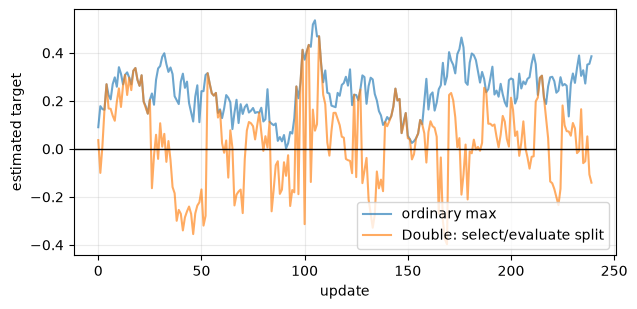

last-60 bias: 0.286 0.044


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(8)
ordinary, double = [], []
q_online = np.zeros(8); q_target = np.zeros(8)
for step in range(240):
    # 所有动作真实价值都是 0，只观测到零均值噪声。
    sample_online = rng.normal(0, 1, size=8)
    sample_target = rng.normal(0, 1, size=8)
    q_online += 0.06 * (sample_online - q_online)
    q_target += 0.06 * (sample_target - q_target)
    ordinary.append(q_target.max())
    chosen = q_online.argmax()
    double.append(q_target[chosen])

plt.figure(figsize=(7, 3.2)); plt.plot(ordinary, alpha=.65, label="ordinary max")
plt.plot(double, alpha=.65, label="Double: select/evaluate split")
plt.axhline(0, color="black", linewidth=1); plt.xlabel("update"); plt.ylabel("estimated target")
plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("last-60 bias:", round(np.mean(ordinary[-60:]), 3), round(np.mean(double[-60:]), 3))


### 曲线怎么读

真实价值为 0，普通 max 曲线通常保持正偏；Double 曲线围绕 0 波动。它展示的是统计偏差，不代表每个时间点 Double 都更低。

### 调参过程：一次只改变一个因素

- 先复现 tuned DQN baseline，再逐个加入 Double、n-step、PER。
- 每次改动都保持训练帧数、评估 epsilon 和种子一致。
- Rainbow 组合后做 ablation，确认每个组件在当前环境确有贡献。

### 失败案例复盘

- online 和 target 都用同一个 `max`，代码名字叫 Double 但算法没变。
- PER 忘记 importance weights，比较结果带采样偏差。
- distributional projection 后概率和不为 1，却继续训练。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 一次只加一种扩展并保留 baseline，才能判断收益来自哪里。
- PER 更新 priority 后要防止零概率，并处理重要性权重的 shape。
- distributional projection 最容易出现质量丢失，要断言每行概率和接近 1。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

构造 online 与 target Q 值，让普通 DQN 的目标比 Double DQN 高很多；说明这与过估计的关系。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

例如 online=`[0,10]`、target=`[100,0]`。普通 DQN target 取 100；Double DQN 先由 online 选动作 1，再在 target 读取 0。这个极端例子清楚显示普通 max 可能选择 target 网络偶然高估的动作。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 每个 DQN 扩展都应对应明确问题。
- Double 分离动作选择和价值评价。
- Dueling 分离状态价值和相对动作优势。
- PER 改变采样分布，需要重要性权重。
- Rainbow 是多项兼容扩展的组合，不是一个神秘新 loss。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**Double DQN 为什么仍然需要 target network？Dueling 中为什么要减 advantage 的均值？

<details>
<summary>展开答案</summary>

Double 仍需 target network 提供相对稳定的评价。减均值用于解决 $V+A$ 分解的不唯一性，并让 value 对应各动作 Q 的平均基线。
</details>


## 17. 与前后章节连接

第 9 章不再改变 Bellman 数学，而是优化同一算法的数据生成与计算吞吐；第 18 章会重新深入探索机制。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

NoisyNet 把可学习噪声注入线性层；categorical DQN 在固定 support 上预测回报分布；Rainbow 常组合 n-step、Double、Dueling、PER、Noisy 与 distributional 方法。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-08) · [← 学习索引](../README.md)
